# CFPB Mortgage Complaint Volume Forecasting

Goal: Test whether historical complaint patterns can predict near-term weekly mortgage complaint volume.

In [1]:
##%pip install scikit-learn

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit

In [3]:
complaints = pd.read_csv("../data/complaints.csv")

complaints["Date received"] = pd.to_datetime(
    complaints["Date received"],
    utc=True
)

In [4]:
print(complaints.shape)
print(complaints["Date received"].min(), complaints["Date received"].max())
print(complaints["Complaint ID"].nunique())


(98933, 15)
2022-10-01 00:06:38+00:00 2026-09-30 16:08:27+00:00
98933


In [5]:
weekly_complaints = complaints.groupby(pd.Grouper(key="Date received", freq="W"))["Complaint ID"].count().reset_index()

In [6]:
print(weekly_complaints.head())
print(weekly_complaints.shape)

              Date received  Complaint ID
0 2022-10-02 00:00:00+00:00            32
1 2022-10-09 00:00:00+00:00           360
2 2022-10-16 00:00:00+00:00           404
3 2022-10-23 00:00:00+00:00           373
4 2022-10-30 00:00:00+00:00           398
(210, 2)


In [7]:
weekly_complaints = weekly_complaints.rename(columns={"Complaint ID":"complaint_count"})

In [8]:

### First and last week are partial weeks since data set starts and ends in middle of weeks
print(weekly_complaints.head(5))
print(weekly_complaints.tail(5))

              Date received  complaint_count
0 2022-10-02 00:00:00+00:00               32
1 2022-10-09 00:00:00+00:00              360
2 2022-10-16 00:00:00+00:00              404
3 2022-10-23 00:00:00+00:00              373
4 2022-10-30 00:00:00+00:00              398
                Date received  complaint_count
205 2026-09-06 00:00:00+00:00              690
206 2026-09-13 00:00:00+00:00              620
207 2026-09-20 00:00:00+00:00              459
208 2026-09-27 00:00:00+00:00               91
209 2026-10-04 00:00:00+00:00               16


In [9]:
recent_daily = (
    complaints[
        complaints["Date received"] >= "2026-09-01"
    ]
    .groupby(pd.Grouper(key="Date received", freq="D"))["Complaint ID"]
    .count()
    .reset_index(name="complaint_count")
)

recent_daily

,Date received,complaint_count
0,2026-09-01 00:00:00+00:00,149
1,2026-09-02 00:00:00+00:00,116
2,2026-09-03 00:00:00+00:00,125
3,2026-09-04 00:00:00+00:00,100
4,2026-09-05 00:00:00+00:00,45
5,2026-09-06 00:00:00+00:00,31
6,2026-09-07 00:00:00+00:00,39
7,2026-09-08 00:00:00+00:00,127
8,2026-09-09 00:00:00+00:00,125
9,2026-09-10 00:00:00+00:00,116


In [10]:
### Only using First usable week: 2022-10-09, Last usable week:  2026-09-13 to avoid incomplete data
weekly_complaints = weekly_complaints[(weekly_complaints['Date received'] >= "2022-10-09") & (weekly_complaints['Date received'] <= "2026-09-13")]

In [11]:
print(weekly_complaints.shape)
print(weekly_complaints.head())
print(weekly_complaints.tail())

(206, 2)
              Date received  complaint_count
1 2022-10-09 00:00:00+00:00              360
2 2022-10-16 00:00:00+00:00              404
3 2022-10-23 00:00:00+00:00              373
4 2022-10-30 00:00:00+00:00              398
5 2022-11-06 00:00:00+00:00              352
                Date received  complaint_count
202 2026-08-16 00:00:00+00:00              600
203 2026-08-23 00:00:00+00:00              655
204 2026-08-30 00:00:00+00:00              676
205 2026-09-06 00:00:00+00:00              690
206 2026-09-13 00:00:00+00:00              620


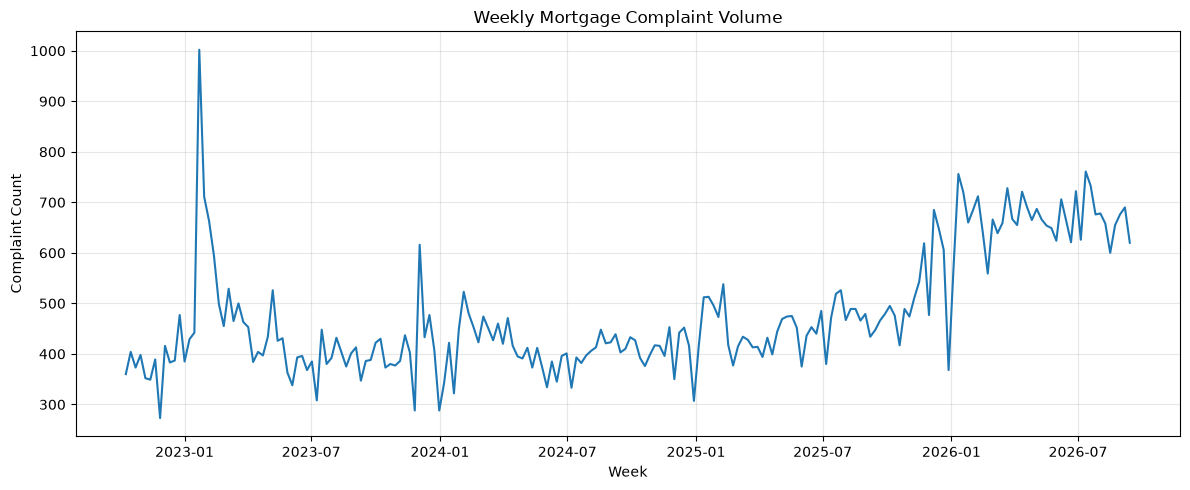

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    weekly_complaints["Date received"],
    weekly_complaints["complaint_count"]
)

plt.title("Weekly Mortgage Complaint Volume")
plt.xlabel("Week")
plt.ylabel("Complaint Count")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [13]:
weekly_complaints["complaint_count"].describe()

count     206.000000
mean      477.354369
std       118.369062
min       273.000000
25%       396.250000
50%       436.500000
75%       522.000000
max      1002.000000
Name: complaint_count, dtype: float64

In [14]:
model_data = weekly_complaints.copy()

In [15]:
model_data["lag_1"] = (model_data["complaint_count"].shift(1))
model_data["lag_2"] = (model_data["complaint_count"].shift(2))
model_data["lag_4"] = (model_data["complaint_count"].shift(4))

model_data.head(8)

,Date received,complaint_count,lag_1,lag_2,lag_4
1,2022-10-09 00:00:00+00:00,360,NaN,NaN,NaN
2,2022-10-16 00:00:00+00:00,404,360.0,NaN,NaN
3,2022-10-23 00:00:00+00:00,373,404.0,360.0,NaN
4,2022-10-30 00:00:00+00:00,398,373.0,404.0,NaN
5,2022-11-06 00:00:00+00:00,352,398.0,373.0,360.0
6,2022-11-13 00:00:00+00:00,349,352.0,398.0,404.0
7,2022-11-20 00:00:00+00:00,389,349.0,352.0,373.0
8,2022-11-27 00:00:00+00:00,273,389.0,349.0,398.0


In [16]:
model_data["rolling_4"] = (
    model_data["complaint_count"]
    .shift(1)
    .rolling(window=4)
    .mean()
)
model_data["rolling_8"] = (
    model_data["complaint_count"]
    .shift(1)
    .rolling(window=8)
    .mean()
)
model_data.head(10)

,Date received,complaint_count,lag_1,lag_2,lag_4,rolling_4,rolling_8
1,2022-10-09 00:00:00+00:00,360,NaN,NaN,NaN,NaN,NaN
2,2022-10-16 00:00:00+00:00,404,360.0,NaN,NaN,NaN,NaN
3,2022-10-23 00:00:00+00:00,373,404.0,360.0,NaN,NaN,NaN
4,2022-10-30 00:00:00+00:00,398,373.0,404.0,NaN,NaN,NaN
5,2022-11-06 00:00:00+00:00,352,398.0,373.0,360.0,383.75,NaN
6,2022-11-13 00:00:00+00:00,349,352.0,398.0,404.0,381.75,NaN
7,2022-11-20 00:00:00+00:00,389,349.0,352.0,373.0,368.00,NaN
8,2022-11-27 00:00:00+00:00,273,389.0,349.0,398.0,372.00,NaN
9,2022-12-04 00:00:00+00:00,416,273.0,389.0,352.0,340.75,362.25
10,2022-12-11 00:00:00+00:00,383,416.0,273.0,349.0,356.75,369.25


In [17]:
model_data = model_data.dropna().copy()
print(model_data.shape)
print(model_data.head())

(198, 7)
               Date received  complaint_count  lag_1  lag_2  lag_4  rolling_4  \
9  2022-12-04 00:00:00+00:00              416  273.0  389.0  352.0     340.75   
10 2022-12-11 00:00:00+00:00              383  416.0  273.0  349.0     356.75   
11 2022-12-18 00:00:00+00:00              387  383.0  416.0  389.0     365.25   
12 2022-12-25 00:00:00+00:00              477  387.0  383.0  273.0     364.75   
13 2023-01-01 00:00:00+00:00              385  477.0  387.0  416.0     415.75   

    rolling_8  
9     362.250  
10    369.250  
11    366.625  
12    368.375  
13    378.250  


In [18]:
features = [
    "lag_1",
    "lag_2",
    "lag_4",
    "rolling_4",
    "rolling_8"
]

split_index = int(len(model_data) * 0.8) ## 80% of data to test, 20% to train

In [19]:
print(split_index)
print(model_data.iloc[split_index]["Date received"])

158
2025-12-14 00:00:00+00:00


In [20]:
X_train = model_data[features].iloc[:split_index]
X_test = model_data[features].iloc[split_index:]

y_train = model_data["complaint_count"].iloc[:split_index]
y_test = model_data["complaint_count"].iloc[split_index:]

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(158, 5)
(40, 5)
(158,)
(40,)


In [22]:
### Calculating naive baseline
baseline_pred = X_test["lag_1"]

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_mae

58.325

So if we simply predict that next week will equal last week, we're off by about 58 complaints per week on average.

Any sklearn model now has to beat 58.325 to add predictive value.

In [25]:
linear_model = LinearRegression()
linear_pred = (linear_model
    .fit(X_train, y_train)
    .predict(X_test)
)

linear_mae = mean_absolute_error(
    y_test,
    linear_pred
)

linear_mae

90.22654214186463

In [27]:
print("Train mean:", y_train.mean())
print("Test mean:", y_test.mean())
print("Train max:", y_train.max())
print("Test max:", y_test.max())

Train mean: 437.0759493670886
Test mean: 659.475
Train max: 1002
Test max: 761


In [29]:
random_forest = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)
random_forest.fit(X_train, y_train)

rf_pred = random_forest.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)

rf_mae

117.149375

In [30]:
print("Actual test mean:", y_test.mean())
print("Baseline prediction mean:", baseline_pred.mean())
print("Linear prediction mean:", linear_pred.mean())
print("Random Forest prediction mean:", rf_pred.mean())

print("Linear prediction range:", linear_pred.min(), linear_pred.max())
print("RF prediction range:", rf_pred.min(), rf_pred.max())

Actual test mean: 659.475
Baseline prediction mean: 661.1
Linear prediction mean: 579.9137256785947
Random Forest prediction mean: 552.457875
Linear prediction range: 453.3795373280985 628.1249182803797
RF prediction range: 408.035 595.37


## Forecast Model Comparison

Three approaches were evaluated for predicting weekly CFPB mortgage complaint volume:

| Model | MAE |
|---|---:|
| Naive Baseline | **58.33** |
| Linear Regression | 90.23 |
| Random Forest | 117.15 |

### Naive Baseline

The naive baseline predicts that the next week's complaint volume will equal the previous week's complaint volume.

Despite being the simplest approach, it produced the **lowest prediction error**, with an MAE of **58.33 complaints per week**.

The average baseline prediction during the test period was **661.10 complaints**, compared with an actual test-period average of **659.48 complaints**.

This suggests that complaint volume has strong short-term persistence and that the most recent week's volume contains substantial predictive information.

### Linear Regression

Linear Regression used five historical features:

- 1-week lag
- 2-week lag
- 4-week lag
- 4-week rolling average
- 8-week rolling average

The model produced an MAE of **90.23**, performing substantially worse than the naive baseline.

Its average test-period prediction was approximately **579.91 complaints per week**, nearly 80 complaints below the actual test-period average.

The model's predictions ranged from approximately **453 to 628 complaints**, showing that it systematically underestimated the higher-volume environment observed during the test period.

### Random Forest Regression

Random Forest was introduced to test whether a nonlinear model could capture relationships that Linear Regression could not.

Instead, it produced the highest error:

- **Random Forest MAE:** 117.15
- Average prediction: **552.46 complaints**
- Prediction range: approximately **408–595 complaints**

The highest Random Forest prediction was below the actual **average** weekly complaint volume during the test period.

This indicates that the model struggled to extrapolate beyond the lower-volume patterns represented in the historical training data.

### Distribution Shift

A major difference existed between the training and test periods:

- Training-period average: **437.08 complaints per week**
- Test-period average: **659.48 complaints per week**
- Increase: approximately **51%**

The forecasting period therefore represented a substantially higher-volume regime than most of the historical training data.

Both machine-learning models systematically underpredicted this new regime, while the naive baseline adapted immediately because it continuously uses the most recent week's observed complaint volume.

### Key Finding

> Increasing model complexity did not improve forecasting performance. The simple one-week persistence baseline substantially outperformed both Linear Regression and Random Forest because recent complaint volume adapted more effectively to the structural increase in weekly complaint activity.

This demonstrates the importance of evaluating machine-learning models against simple benchmarks and considering distribution shifts when forecasting time-series data.

In [31]:
forecast_results = pd.DataFrame({
    "Date received": model_data["Date received"].iloc[split_index:].reset_index(drop=True),
    "Actual": y_test.reset_index(drop=True),
    "Naive": baseline_pred.reset_index(drop=True),
    "Linear Regression": linear_pred,
    "Random Forest": rf_pred
})
forecast_results.head()

,Date received,Actual,Naive,Linear Regression,Random Forest
0,2025-12-14 00:00:00+00:00,648,685.0,544.623565,579.660
1,2025-12-21 00:00:00+00:00,606,648.0,572.094883,569.900
2,2025-12-28 00:00:00+00:00,368,606.0,557.606707,570.645
3,2026-01-04 00:00:00+00:00,569,368.0,453.379537,408.035
4,2026-01-11 00:00:00+00:00,756,569.0,479.171854,515.215


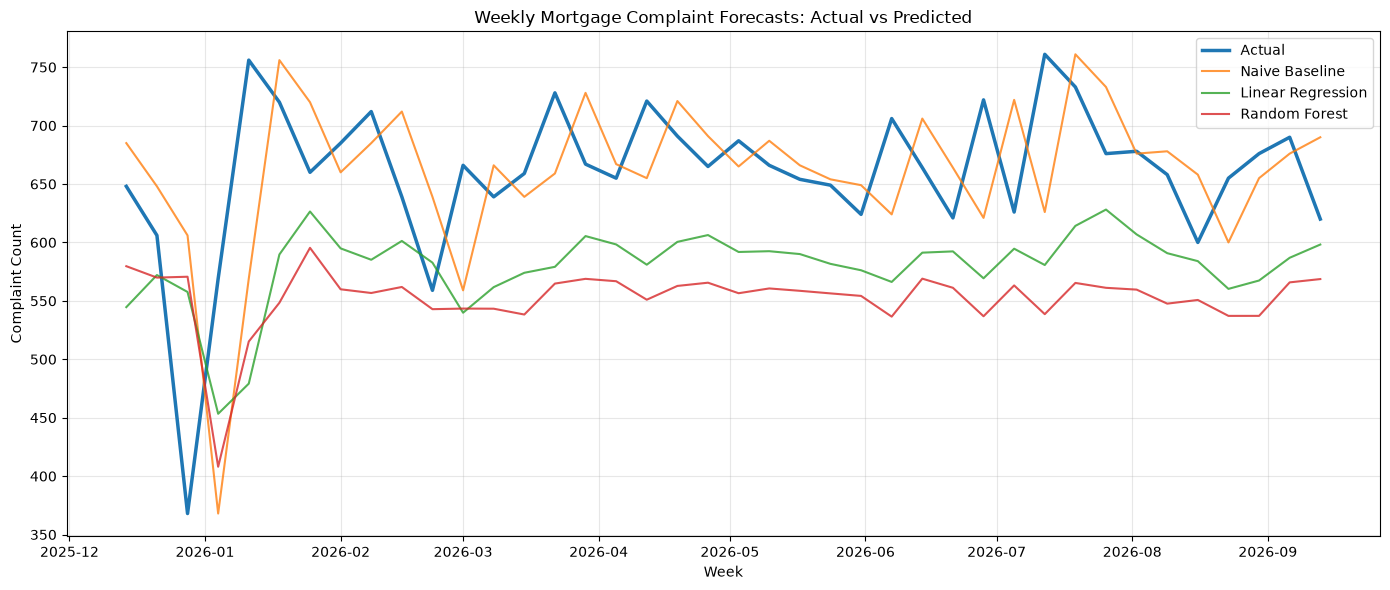

In [32]:
plt.figure(figsize=(14, 6))

plt.plot(
    forecast_results["Date received"],
    forecast_results["Actual"],
    label="Actual",
    linewidth=2.5
)

plt.plot(
    forecast_results["Date received"],
    forecast_results["Naive"],
    label="Naive Baseline",
    alpha=0.8
)

plt.plot(
    forecast_results["Date received"],
    forecast_results["Linear Regression"],
    label="Linear Regression",
    alpha=0.8
)

plt.plot(
    forecast_results["Date received"],
    forecast_results["Random Forest"],
    label="Random Forest",
    alpha=0.8
)

plt.title("Weekly Mortgage Complaint Forecasts: Actual vs Predicted")
plt.xlabel("Week")
plt.ylabel("Complaint Count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [34]:
tscv = TimeSeriesSplit(n_splits=5)

In [ ]:
X = model_data[features]
y = model_data["complaint_count"]

for fold, (train_idx, test_idx) in enumerate(tscv.split(X), start=1):
    print(
        fold,
        len(train_idx),
        len(test_idx),
        train_idx[-1],
        test_idx[0],
        test_idx[-1]
    )

###Fold 1: Train rows   0–32   → Test 33–65
###Fold 2: Train rows   0–65   → Test 66–98
###Fold 3: Train rows   0–98   → Test 99–131
###Fold 4: Train rows   0–131  → Test 132–164
###Fold 5: Train rows   0–164  → Test 165–197

1 33 33 32 33 65
2 66 33 65 66 98
3 99 33 98 99 131
4 132 33 131 132 164
5 165 33 164 165 197
